# Treinamento

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping

In [4]:
df = pd.read_csv('data/dataset_balanceado.csv')

In [5]:
np.random.seed(1)
tf.random.set_seed(1)

In [6]:
X = np.array(df['texto'].tolist(), dtype=object)
y = df['label'].values

In [7]:
# Treino (80%), Teste (20%)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=1, stratify=y
)

print(f"Total de dados: {len(df)} (negativos: {(y==0).sum()}, positivos: {(y==1).sum()})")
print(f"Treino: {len(X_treino)}, Teste: {len(X_teste)}")

Total de dados: 290 (negativos: 145, positivos: 145)
Treino: 232, Teste: 58


In [8]:
# Construção do modelo e camada de vetorização
vectorizer = TextVectorization(
    max_tokens=1000,
    output_sequence_length=100,
    standardize="lower_and_strip_punctuation"
)
vectorizer.adapt(X_treino)

modelo = Sequential([
    vectorizer,
    Embedding(input_dim=1000, output_dim=16, mask_zero=True),
    LSTM(16, dropout=0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

modelo.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Ver as camadas do modelo
modelo(np.array(["teste"], dtype=object))
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (1, 100)               │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (1, 100, 16)           │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (1, 16)                │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 16)                │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 16)                │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 1)                 │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,401 (71.88 KB)

 Trainable params: 18,401 (71.88 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Treinamento
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = modelo.fit(
    X_treino,
    y_treino,
    validation_split=0.2,
    epochs=3,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.5297 - loss: 0.6929 - val_accuracy: 0.5745 - val_loss: 0.6927
Epoch 2/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5514 - loss: 0.6914 - val_accuracy: 0.6170 - val_loss: 0.6926
Epoch 3/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6541 - loss: 0.6884 - val_accuracy: 0.5106 - val_loss: 0.6929


In [10]:
# Avaliação dos dados de teste
y_pred_proba = modelo.predict(tf.constant(X_teste))
y_pred = (y_pred_proba >= 0.5).astype(int).flatten()

print(f"\n Acurácia: {accuracy_score(y_teste, y_pred) * 100:.2f}%")
print("\n Classificação:")
print(classification_report(y_teste, y_pred, target_names=['Negativo (0)', 'Positivo (1)'], zero_division=0))


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step

 Acurácia: 62.07%

 Classificação:
              precision    recall  f1-score   support

Negativo (0)       0.89      0.28      0.42        29
Positivo (1)       0.57      0.97      0.72        29

    accuracy                           0.62        58
   macro avg       0.73      0.62      0.57        58
weighted avg       0.73      0.62      0.57        58



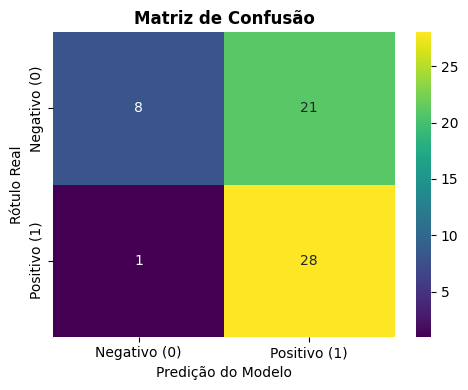

In [11]:
labels = ['Negativo (0)', 'Positivo (1)']

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_teste, y_pred),
    annot=True,
    fmt='d',
    cmap='viridis',
    xticklabels=labels,
    yticklabels=labels
)
plt.title('Matriz de Confusão', fontweight='bold')
plt.xlabel('Predição do Modelo')
plt.ylabel('Rótulo Real')
plt.tight_layout()
plt.savefig('matriz_confusao.png', dpi=300)
plt.show()

In [18]:
# Teste com novas frases
novos_pareceres = [
    "El articulo es excelente, aporta resultados muy interesantes y novedosos.",
    "Trabajo muy malo, falta claridad en la metodologia y los experimentos fallan.",
    "El trabajo presenta graves deficiencias, rechazo la metodologia propuesta."
]

pred_novos = modelo.predict(tf.constant(novos_pareceres))

for txt, prob in zip(novos_pareceres, pred_novos):
    classe = "positivo" if prob[0] >= 0.5 else "negativo"
    print(f"\nParecer: '{txt}' -> Probabilidade: {prob[0]:.4f}, Classificação: {classe}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step

Parecer: 'El articulo es excelente, aporta resultados muy interesantes y novedosos.' -> Probabilidade: 0.5044, Classificação: positivo

Parecer: 'Trabajo muy malo, falta claridad en la metodologia y los experimentos fallan.' -> Probabilidade: 0.5115, Classificação: positivo

Parecer: 'El trabajo presenta graves deficiencias, rechazo la metodologia propuesta.' -> Probabilidade: 0.5092, Classificação: positivo
